In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import sidetable
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

In [2]:
df = pd.read_csv("history.csv")
display(df)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904


In [3]:
# Verificando o formato dos dados
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   object 
 2   SeniorCitizen     5634 non-null   int64  
 3   Partner           5634 non-null   object 
 4   Dependents        5634 non-null   object 
 5   tenure            5634 non-null   object 
 6   PhoneService      5634 non-null   object 
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   object 


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634,2,Male,2835,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,5634.0,NaN,NaN,NaN,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634,2,No,2907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,5634,2,No,3949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,5634,74,1,475,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PhoneService,5634,4,Yes,5041,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Verificando dados nulos e seu percentual
df.stb.missing()

,missing,total,percent
TotalCharges,278,5634,4.934327
gender,0,5634,0.000000
customerID,0,5634,0.000000
Partner,0,5634,0.000000
Dependents,0,5634,0.000000
tenure,0,5634,0.000000
SeniorCitizen,0,5634,0.000000
PhoneService,0,5634,0.000000
MultipleLines,0,5634,0.000000
OnlineSecurity,0,5634,0.000000


In [6]:
print(df.isna().sum())

customerID            0
gender                0
SeniorCitizen         0
Partner               0
Dependents            0
tenure                0
PhoneService          0
MultipleLines         0
InternetService       0
OnlineSecurity        0
OnlineBackup          0
DeviceProtection      0
TechSupport           0
StreamingTV           0
StreamingMovies       0
Contract              0
PaperlessBilling      0
PaymentMethod         0
MonthlyCharges        0
TotalCharges        278
Churn                 0
CustomerFeedback      0
MonthlyIncome         0
dtype: int64


In [7]:
# Verificando dados duplicados
df.duplicated().sum()

np.int64(0)

In [8]:
df1 = df.copy()
display(df1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,Male,0,Yes,Yes,52,Yes,No,DSL,No,...,Yes,No,One year,Yes,Electronic check,68.75,3482.85,No,I have been a customer with this internet prov...,6532
1,6289-CPNLD,Male,0,Yes,Yes,33,Yes,No,DSL,No,...,Yes,Yes,One year,Yes,Mailed check,73.90,2405.05,Yes,I've been a customer with this company for ove...,7634
2,2682-KEVRP,Female,1,No,No,22,Yes,No,No,No internet service,...,No internet service,No internet service,One year,Yes,Mailed check,20.05,417.00,No,I have been a customer with this company for 2...,3628
3,5697-GOMBF,Female,1,Yes,Yes,28,No,No phone service,DSL,No,...,Yes,No,Month-to-month,Yes,Electronic check,35.90,973.65,No,I have been a customer with this internet prov...,7851
4,9717-QEBGU,Male,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.30,144.00,No,I have been using the fiber optic internet ser...,1691
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5629,8909-BOLNL,Male,0,No,No,3,Yes,No,No,No internet service,...,No internet service,No internet service,One year,No,Mailed check,21.20,52.05,No,I have been a customer with this company for 3...,8354
5630,2832-KJCRD,Female,0,No,No,38,Yes,Yes,Fiber optic,No,...,Yes,Yes,Month-to-month,Yes,Electronic check,103.65,3988.50,No,I have been a customer with this company for 3...,9308
5631,7975-JMZNT,Male,0,Yes,No,66,Yes,Yes,DSL,Yes,...,Yes,Yes,Two year,No,Bank transfer (automatic),91.70,6075.90,No,I have been a customer with this DSL internet ...,2113
5632,4250-ZBWLV,Male,0,No,No,68,Yes,Yes,Fiber optic,No,...,Yes,Yes,One year,No,Electronic check,108.45,7176.55,Yes,I have been a customer with this company for o...,3904


In [9]:
# 1. gender: converte Male para 0 e Female para 1
df1['gender'] = df['gender'].map({'Male': 0, 'Female': 1}).astype('Int64')

# 2. SeniorCitizen: mantém 0 (Não) e 1 (Sim), convertendo para tipo inteiro
df1['SeniorCitizen'] = df1['SeniorCitizen'].astype('Int64')

# 3. Partner: converte No para 0 e Yes para 1
df1['Partner'] = df['Partner'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 4. Dependents: converte No para 0 e Yes para 1
df1['Dependents'] = df['Dependents'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 5. tenure: converte os valores para números inteiros, valores inválidos, como 'unknown', são transformados em NaN, utiliza Int64 (nullable) para permitir valores ausentes
df1['tenure'] = pd.to_numeric(df['tenure'], errors='coerce').astype('Int64')

# 6. PhoneService: remove espaços e normaliza letras maiúsculas/minúsculas, em seguida, converte no para 0 e yes para 1
df1['PhoneService'] = (
    df['PhoneService']
    .str.strip()
    .str.lower()
    .map({'no': 0, 'yes': 1})
    .astype('Int64')
)

# 7. PaperlessBilling: converte No para 0 e Yes para 1
df1['PaperlessBilling'] = df['PaperlessBilling'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 8. Churn: converte No para 0 e Yes para 1, é a variável-alvo (target) do modelo preditivo
df1['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype('Int64')

# 9. Verificação: exibe os tipos de dados após as transformações
df1.info()

# 10. Verificação: exibe a quantidade de valores ausentes nas colunas tratadas
colunas_tratadas = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'tenure', 'PhoneService', 'PaperlessBilling', 'Churn'
]

print("\nValores ausentes após as transformações:")
print(df1[colunas_tratadas].isna().sum())

# 11. Visualização: exibe as primeiras cinco linhas da base transformada
display(df1.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        5634 non-null   object 
 1   gender            5634 non-null   Int64  
 2   SeniorCitizen     5634 non-null   Int64  
 3   Partner           5634 non-null   Int64  
 4   Dependents        5634 non-null   Int64  
 5   tenure            5615 non-null   Int64  
 6   PhoneService      5634 non-null   Int64  
 7   MultipleLines     5634 non-null   object 
 8   InternetService   5634 non-null   object 
 9   OnlineSecurity    5634 non-null   object 
 10  OnlineBackup      5634 non-null   object 
 11  DeviceProtection  5634 non-null   object 
 12  TechSupport       5634 non-null   object 
 13  StreamingTV       5634 non-null   object 
 14  StreamingMovies   5634 non-null   object 
 15  Contract          5634 non-null   object 
 16  PaperlessBilling  5634 non-null   Int64  


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,CustomerFeedback,MonthlyIncome
0,4578-PHJYZ,0,0,1,1,52,1,No,DSL,No,...,Yes,No,One year,1,Electronic check,68.75,3482.85,0,I have been a customer with this internet prov...,6532
1,6289-CPNLD,0,0,1,1,33,1,No,DSL,No,...,Yes,Yes,One year,1,Mailed check,73.90,2405.05,1,I've been a customer with this company for ove...,7634
2,2682-KEVRP,1,1,0,0,22,1,No,No,No internet service,...,No internet service,No internet service,One year,1,Mailed check,20.05,417.00,0,I have been a customer with this company for 2...,3628
3,5697-GOMBF,1,1,1,1,28,0,No phone service,DSL,No,...,Yes,No,Month-to-month,1,Electronic check,35.90,973.65,0,I have been a customer with this internet prov...,7851
4,9717-QEBGU,0,0,0,0,2,1,No,Fiber optic,No,...,No,No,Month-to-month,1,Electronic check,70.30,144.00,0,I have been using the fiber optic internet ser...,1691


In [10]:
df1.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634.0,<NA>,<NA>,<NA>,0.496805,0.500034,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5634.0,<NA>,<NA>,<NA>,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634.0,<NA>,<NA>,<NA>,0.484026,0.499789,0.0,0.0,0.0,1.0,1.0
Dependents,5634.0,<NA>,<NA>,<NA>,0.299077,0.457894,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,<NA>,<NA>,<NA>,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5634.0,<NA>,<NA>,<NA>,0.900071,0.299932,0.0,1.0,1.0,1.0,1.0
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# 1. PaymentMethod: aplica One-Hot Encoding às 4 categorias de pagamento
# drop_first=False mantém todas as categorias
# dtype='int64' garante que os valores sejam 0 ou 1
payment_dummies = pd.get_dummies(
    df1['PaymentMethod'],
    prefix='PaymentMethod',
    drop_first=False,
    dtype='int64'
)

# 2. Adiciona as 4 novas colunas ao DataFrame
df1 = pd.concat([df1, payment_dummies], axis=1)

# 3. Remove a coluna categórica original
df1 = df1.drop(columns=['PaymentMethod'])

# 4. Verifica as novas colunas criadas
display(payment_dummies.head())

# 5. Confere a estrutura atualizada da base
df1.info()


,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0
1,0,0,0,1
2,0,0,0,1
3,0,0,1,0
4,0,0,1,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 26 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   customerID                               5634 non-null   object 
 1   gender                                   5634 non-null   Int64  
 2   SeniorCitizen                            5634 non-null   Int64  
 3   Partner                                  5634 non-null   Int64  
 4   Dependents                               5634 non-null   Int64  
 5   tenure                                   5615 non-null   Int64  
 6   PhoneService                             5634 non-null   Int64  
 7   MultipleLines                            5634 non-null   object 
 8   InternetService                          5634 non-null   object 
 9   OnlineSecurity                           5634 non-null   object 
 10  OnlineBackup                             5634 no

In [12]:
df1.describe(include='all').T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,5634,5634,4578-PHJYZ,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,5634.0,<NA>,<NA>,<NA>,0.496805,0.500034,0.0,0.0,0.0,1.0,1.0
SeniorCitizen,5634.0,<NA>,<NA>,<NA>,0.164714,0.370955,0.0,0.0,0.0,0.0,1.0
Partner,5634.0,<NA>,<NA>,<NA>,0.484026,0.499789,0.0,0.0,0.0,1.0,1.0
Dependents,5634.0,<NA>,<NA>,<NA>,0.299077,0.457894,0.0,0.0,0.0,1.0,1.0
tenure,5615.0,<NA>,<NA>,<NA>,32.306144,24.48471,0.0,9.0,29.0,55.0,72.0
PhoneService,5634.0,<NA>,<NA>,<NA>,0.900071,0.299932,0.0,1.0,1.0,1.0,1.0
MultipleLines,5634,3,No,2704,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,5634,3,Fiber optic,2477,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,5634,3,No,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# Analisando visualmente as causas dos cancelamentos
# Remove customerID apenas se a coluna existir
df1 = df1.drop(columns="customerID", errors="ignore")

# Gera os histogramas das variáveis
for coluna in df1.columns:
    grafico = px.histogram(df1, x=coluna, color="Churn")
    grafico.show()

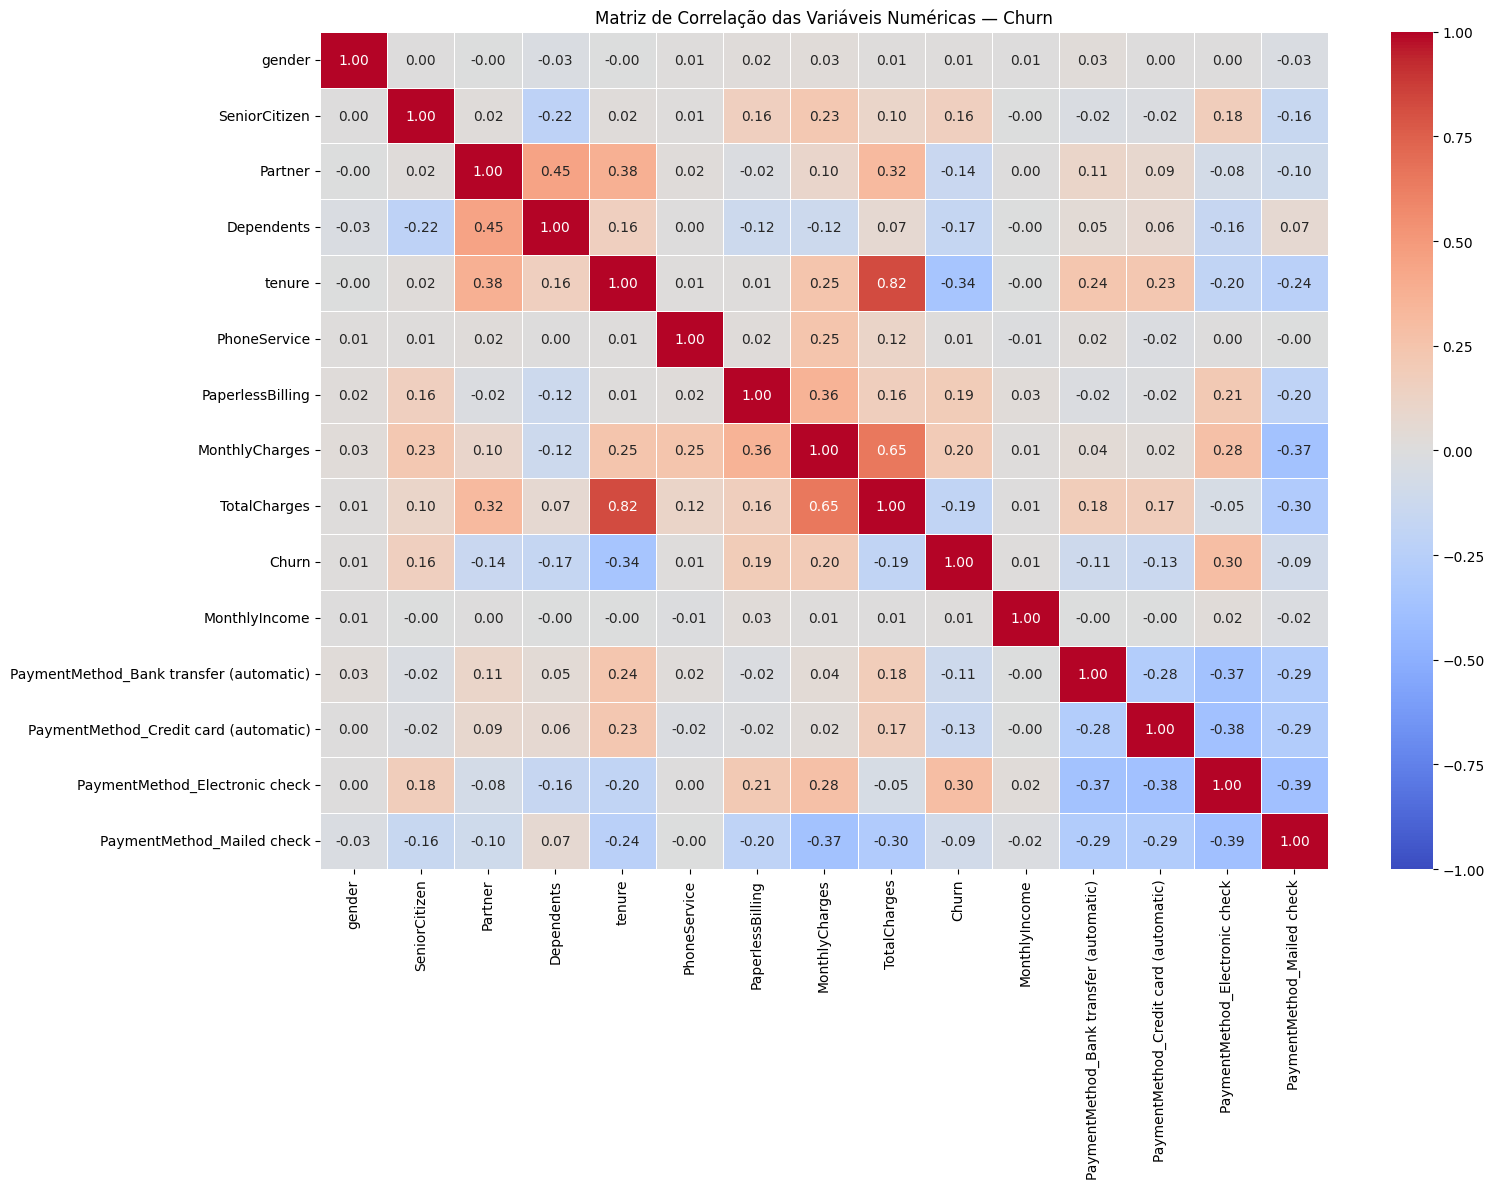

In [14]:
# 1. Seleciona todas as variáveis numéricas do DataFrame df1
# Inclui int64, Int64 e float64, além das variáveis binárias (0/1)
num_cols = df1.select_dtypes(include='number').columns

# 2. Calcula a matriz de correlação de Pearson
# Valores variam de -1 (correlação negativa) a +1 (positiva)
corr = df1[num_cols].corr(method='pearson')

# 3. Define o tamanho do gráfico de acordo com a quantidade de variáveis
plt.figure(figsize=(16, 12))

# 4. Cria o mapa de calor das correlações
sns.heatmap(
    corr,
    annot=True,         # Exibe os coeficientes nas células
    fmt='.2f',          # Exibe duas casas decimais
    cmap='coolwarm',    # Azul = negativa; vermelho = positiva
    vmin=-1,            # Limite inferior da escala
    vmax=1,             # Limite superior da escala
    center=0,           # Centraliza a escala no zero
    linewidths=0.5      # Adiciona linhas entre as células
)

# 5. Configura o título e ajusta o layout
plt.title('Matriz de Correlação das Variáveis Numéricas — Churn')
plt.tight_layout()

# 6. Exibe o gráfico
plt.show()


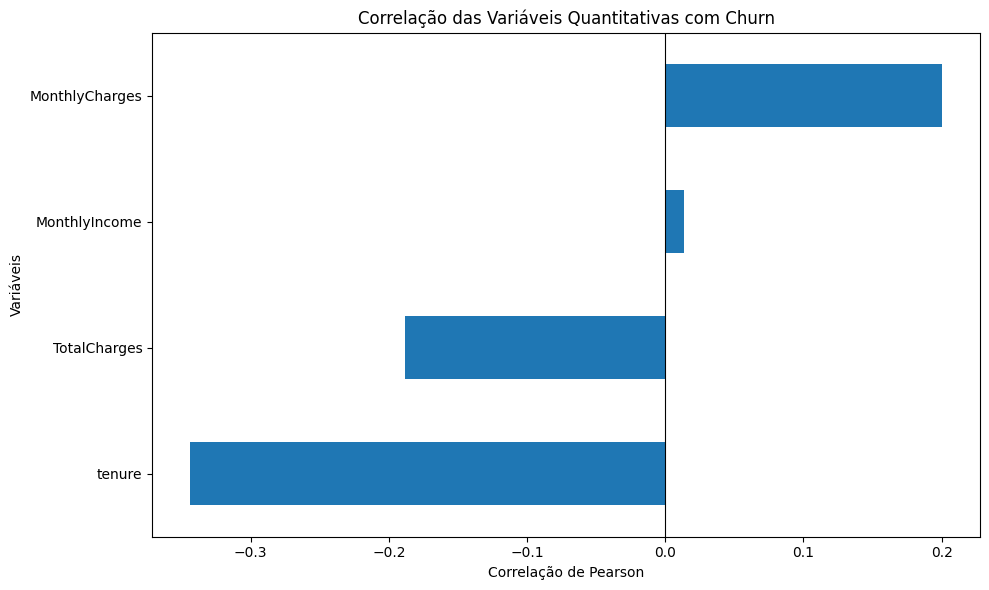

In [15]:
# 1. Define explicitamente as variáveis quantitativas
num_cols = [
    'tenure',
    'MonthlyIncome',
    'MonthlyCharges',
    'TotalCharges'
]

# 2. Calcula a correlação de Pearson com Churn
corr_churn = (
    df1[num_cols + ['Churn']]
    .corr(method='pearson')['Churn']
    .drop('Churn')
    .sort_values()
)

# 3. Define o tamanho do gráfico
plt.figure(figsize=(10, 6))

# 4. Cria o gráfico de barras horizontais
corr_churn.plot(kind='barh')

# 5. Adiciona uma linha de referência para correlação zero
plt.axvline(x=0, color='black', linewidth=0.8)

# 6. Configura título e eixos
plt.title('Correlação das Variáveis Quantitativas com Churn')
plt.xlabel('Correlação de Pearson')
plt.ylabel('Variáveis')

# 7. Ajusta o layout e exibe o gráfico
plt.tight_layout()
plt.show()



In [16]:
# 1. Seleciona as variáveis categóricas ainda armazenadas como texto
cat_cols = df1.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# 2. Define as variáveis binárias convertidas para 0 e 1
bin_cols = [
    'gender', 'SeniorCitizen', 'Partner',
    'Dependents', 'PhoneService', 'PaperlessBilling'
]

# 3. Identifica todas as colunas criadas pelo One-Hot Encoding
# Cada modalidade de pagamento será analisada separadamente
payment_cols = [
    col for col in df1.columns
    if col.startswith('PaymentMethod_')
]

# 4. Consolida todas as variáveis categóricas
cat_cols = list(dict.fromkeys(cat_cols + bin_cols + payment_cols))

# 5. Exclui identificadores, textos livres e a variável-alvo
cat_cols = [
    col for col in cat_cols
    if col in df1.columns
    and col not in ['customerID', 'CustomerFeedback', 'Churn']
]

# 6. Cria a lista para armazenar os resultados
resultados = []

# 7. Executa o teste Qui-Quadrado para cada variável categórica
for col in cat_cols:

    # Cria a tabela de contingência entre a variável e Churn
    tabela = pd.crosstab(df1[col], df1['Churn'])

    # Ignora variáveis que não possuem categorias suficientes
    if tabela.shape[0] < 2 or tabela.shape[1] < 2:
        continue

    # Executa o teste Qui-Quadrado de independência
    chi2, p, dof, expected = chi2_contingency(tabela)

    # Armazena os resultados
    resultados.append({
        'variavel': col,
        'chi2': chi2,
        'p_value': p,
        'GL': dof,
        'n_categorias': tabela.shape[0],
        'significativo_5%': 'Sim' if p < 0.05 else 'Não',
        'freq_esperada_min': expected.min()
    })

# 8. Organiza os resultados pelo menor p-value
df_chi2 = (
    pd.DataFrame(resultados)
    .sort_values('p_value')
    .reset_index(drop=True)
)

# 9. Exibe a tabela completa
display(df_chi2)


,variavel,chi2,p_value,GL,n_categorias,significativo_5%,freq_esperada_min
0,Contract,919.446936,2.211234e-200,2,3,Sim,317.137380
1,OnlineSecurity,682.351790,6.748255e-149,2,3,Sim,329.150160
2,TechSupport,672.591820,8.882640e-147,2,3,Sim,329.150160
3,InternetService,590.639494,5.549622e-129,2,3,Sim,329.150160
4,PaymentMethod_Electronic check,491.570029,6.489223e-109,1,2,Sim,504.002840
5,OnlineBackup,477.814912,1.753114e-104,2,3,Sim,329.150160
6,DeviceProtection,440.920724,1.800036e-96,2,3,Sim,329.150160
7,StreamingMovies,314.159918,6.040050e-69,2,3,Sim,329.150160
8,StreamingTV,308.350028,1.103169e-67,2,3,Sim,329.150160
9,PaperlessBilling,202.514865,5.902674e-46,1,2,Sim,615.855165


In [17]:

# 1. Define os serviços adicionais que dependem da internet
servicos_internet = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# 2. Verifica inconsistências entre PhoneService e MultipleLines
print("PhoneService x MultipleLines:")
display(pd.crosstab(df1['PhoneService'], df1['MultipleLines']))

# 3. Verifica inconsistências entre InternetService e os serviços adicionais
for coluna in servicos_internet:
    print(f"\nInternetService x {coluna}:")
    display(pd.crosstab(df1['InternetService'], df1[coluna]))


PhoneService x MultipleLines:


MultipleLines,No,No phone service,Yes
PhoneService,,,
0,0,563,0
1,2704,0,2367



InternetService x OnlineSecurity:


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,990,0,934
Fiber optic,1813,0,664
No,0,1233,0



InternetService x OnlineBackup:


OnlineBackup,No,No internet service,Yes
InternetService,,,
DSL,1064,0,860
Fiber optic,1393,0,1084
No,0,1233,0


... (4 outputs left out)


InternetService x StreamingTV:


StreamingTV,No,No internet service,Yes
InternetService,,,
DSL,1146,0,778
Fiber optic,1073,0,1404
No,0,1233,0



InternetService x StreamingMovies:


StreamingMovies,No,No internet service,Yes
InternetService,,,
DSL,1141,0,783
Fiber optic,1083,0,1394
No,0,1233,0


In [18]:
# 1. MultipleLines: converte para variável binária
# Yes = 1, No = 0, No phone service = 0
# A ausência de serviço telefônico continua identificável em PhoneService
df1['MultipleLines'] = (
    df['MultipleLines']
    .map({'Yes': 1, 'No': 0, 'No phone service': 0})
    .astype('Int64')
)

# 2. Define as seis variáveis de serviços adicionais de internet
servicos_internet = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# 3. Converte os serviços adicionais para variáveis binárias
# Yes = 1, No = 0, No internet service = 0
# A ausência de internet continuará identificável em InternetService
for coluna in servicos_internet:
    df1[coluna] = (
        df[coluna]
        .map({'Yes': 1, 'No': 0, 'No internet service': 0})
        .astype('Int64')
    )

# 4. Aplica One-Hot Encoding às três categorias de InternetService
# Mantém as três categorias e utiliza inteiros 0 e 1
internet_dummies = pd.get_dummies(
    df['InternetService'],
    prefix='InternetService',
    drop_first=False,
    dtype='int64'
)

# 5. Remove a variável categórica original
df1 = df1.drop(columns=['InternetService'])

# 6. Adiciona as três colunas geradas pelo One-Hot Encoding
df1 = pd.concat([df1, internet_dummies], axis=1)

# 7. Verifica os tipos de dados após as transformações
df1.info()

# 8. Exibe as primeiras linhas das variáveis transformadas
colunas_transformadas = (
    ['MultipleLines']
    + servicos_internet
    + internet_dummies.columns.tolist()
)

display(df1[colunas_transformadas].head())

# 9. Verifica se as transformações criaram valores ausentes
print("\nValores ausentes após as transformações:")
print(df1[colunas_transformadas].isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5634 non-null   Int64  
 1   SeniorCitizen                            5634 non-null   Int64  
 2   Partner                                  5634 non-null   Int64  
 3   Dependents                               5634 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5634 non-null   Int64  
 6   MultipleLines                            5634 non-null   Int64  
 7   OnlineSecurity                           5634 non-null   Int64  
 8   OnlineBackup                             5634 non-null   Int64  
 9   DeviceProtection                         5634 non-null   Int64  
 10  TechSupport                              5634 no

,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,0,0,1,1,1,1,0,1,0,0
1,0,0,0,1,1,1,1,1,0,0
2,0,0,0,0,0,0,0,0,0,1
3,0,0,0,0,0,1,0,1,0,0
4,0,0,0,0,0,0,0,0,1,0



Valores ausentes após as transformações:
MultipleLines                  0
OnlineSecurity                 0
OnlineBackup                   0
DeviceProtection               0
TechSupport                    0
StreamingTV                    0
StreamingMovies                0
InternetService_DSL            0
InternetService_Fiber optic    0
InternetService_No             0
dtype: int64


In [21]:
df1.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,Churn,CustomerFeedback,MonthlyIncome,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,InternetService_DSL,InternetService_Fiber optic,InternetService_No
0,0,0,1,1,52,1,0,0,1,1,...,0,I have been a customer with this internet prov...,6532,0,0,1,0,1,0,0
1,0,0,1,1,33,1,0,0,0,1,...,1,I've been a customer with this company for ove...,7634,0,0,0,1,1,0,0
2,1,1,0,0,22,1,0,0,0,0,...,0,I have been a customer with this company for 2...,3628,0,0,0,1,0,0,1
3,1,1,1,1,28,0,0,0,0,0,...,0,I have been a customer with this internet prov...,7851,0,0,1,0,1,0,0
4,0,0,0,0,2,1,0,0,0,0,...,0,I have been using the fiber optic internet ser...,1691,0,0,1,0,0,1,0


In [22]:
# 1. Contract: aplica One-Hot Encoding às três modalidades contratuais
# drop_first=False mantém todas as categorias
# dtype='int64' representa as categorias com 0 e 1
contract_dummies = pd.get_dummies(
    df1['Contract'],
    prefix='Contract',
    drop_first=False,
    dtype='int64'
)

# 2. Adiciona as novas colunas ao DataFrame
df1 = pd.concat([df1, contract_dummies], axis=1)

# 3. Remove a coluna categórica original
df1 = df1.drop(columns=['Contract'])

# 4. Verifica as três colunas criadas
display(contract_dummies.head())

# 5. Confirma a estrutura da base
df1.info()


,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0
1,0,1,0
2,0,1,0
3,1,0,0
4,1,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 29 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   gender                                   5634 non-null   Int64  
 1   SeniorCitizen                            5634 non-null   Int64  
 2   Partner                                  5634 non-null   Int64  
 3   Dependents                               5634 non-null   Int64  
 4   tenure                                   5615 non-null   Int64  
 5   PhoneService                             5634 non-null   Int64  
 6   MultipleLines                            5634 non-null   Int64  
 7   OnlineSecurity                           5634 non-null   Int64  
 8   OnlineBackup                             5634 non-null   Int64  
 9   DeviceProtection                         5634 non-null   Int64  
 10  TechSupport                              5634 no

,tenure,MonthlyCharges,TotalCharges,tenure_estimado,MonthlyIncome,Churn
1059,<NA>,86.60,6350.50,73.33,3093,0
1097,<NA>,106.10,NaN,NaN,4702,1
1791,<NA>,89.75,1052.40,11.73,7709,1
1984,<NA>,114.05,8289.20,72.68,4415,0
2361,<NA>,99.25,2186.40,22.03,9165,1
2372,<NA>,19.55,19.55,1.00,4751,0
2641,<NA>,99.15,3615.60,36.47,4701,1
2896,<NA>,61.45,4131.20,67.23,2494,0
2936,<NA>,20.00,288.05,14.40,4749,1
2959,<NA>,104.10,7040.85,67.64,8867,1


Comparação entre os grupos:


,clientes,taxa_churn,mensalidade_media,renda_media,totalcharges_medio
tenure_ausente,,,,,
False,5615,26.64,64.61,5107.39,2270.97
True,19,42.11,63.83,4362.42,2542.70


Avaliação da estimativa de tenure:
Registros avaliados: 5338
Erro absoluto médio: 0.76 meses
Erro absoluto mediano: 0.50 meses
Estimativas com erro até 1 mês: 72.29%


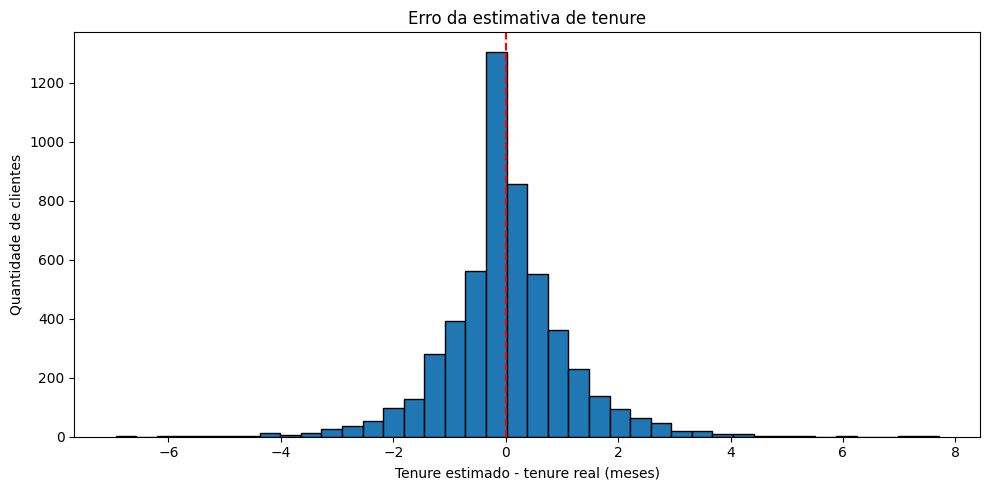

In [23]:
# 1. Cria uma cópia da base para investigação
# Mantém df1 inalterado
df_tenure = df1.copy()

# 2. Identifica os registros com tenure ausente
df_tenure['tenure_ausente'] = df_tenure['tenure'].isna()

# 3. Calcula uma estimativa de tenure a partir das cobranças
# Esta estimativa é apenas exploratória, não é uma imputação
df_tenure['tenure_estimado'] = (
    df_tenure['TotalCharges'] / df_tenure['MonthlyCharges']
)

# 4. Exibe os registros com tenure ausente
colunas_analise = [
    'tenure', 'MonthlyCharges', 'TotalCharges',
    'tenure_estimado', 'MonthlyIncome', 'Churn'
]

display(
    df_tenure.loc[
        df_tenure['tenure_ausente'],
        colunas_analise
    ].round(2)
)

# 5. Compara os grupos com e sem tenure ausente
resumo = df_tenure.groupby('tenure_ausente').agg(
    clientes=('Churn', 'size'),
    taxa_churn=('Churn', 'mean'),
    mensalidade_media=('MonthlyCharges', 'mean'),
    renda_media=('MonthlyIncome', 'mean'),
    totalcharges_medio=('TotalCharges', 'mean')
)

# Converte a taxa de churn para percentual
resumo['taxa_churn'] *= 100

print("Comparação entre os grupos:")
display(resumo.round(2))

# 6. Avalia a precisão da estimativa nos registros conhecidos
validacao = df_tenure.dropna(
    subset=['tenure', 'tenure_estimado']
).copy()

# Calcula a diferença entre tenure real e estimado
validacao['erro'] = (
    validacao['tenure_estimado'] - validacao['tenure']
)

# Calcula o erro absoluto
validacao['erro_absoluto'] = validacao['erro'].abs()

print("Avaliação da estimativa de tenure:")
print(f"Registros avaliados: {len(validacao)}")
print(f"Erro absoluto médio: {validacao['erro_absoluto'].mean():.2f} meses")
print(f"Erro absoluto mediano: {validacao['erro_absoluto'].median():.2f} meses")

# Percentual de estimativas com erro de até 1 mês
precisao_1_mes = (
    (validacao['erro_absoluto'] <= 1).mean() * 100
)

print(f"Estimativas com erro até 1 mês: {precisao_1_mes:.2f}%")

# 7. Visualiza a distribuição dos erros
plt.figure(figsize=(10, 5))
plt.hist(validacao['erro'], bins=40, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')
plt.title('Erro da estimativa de tenure')
plt.xlabel('Tenure estimado - tenure real (meses)')
plt.ylabel('Quantidade de clientes')
plt.tight_layout()
plt.show()


In [24]:

# 1. Cria faixas de tempo de relacionamento
faixas = [-1, 6, 12, 24, 36, 48, 60, 72]

rotulos = [
    '0–6 meses',
    '7–12 meses',
    '13–24 meses',
    '25–36 meses',
    '37–48 meses',
    '49–60 meses',
    '61–72 meses'
]

# 2. Classifica os clientes com tenure conhecido por faixa
validacao['faixa_tenure'] = pd.cut(
    validacao['tenure'].astype(float),
    bins=faixas,
    labels=rotulos
)

# 3. Calcula o erro médio absoluto e a precisão por faixa
resultado_faixas = (
    validacao.groupby('faixa_tenure', observed=True)
    .agg(
        clientes=('erro_absoluto', 'size'),
        erro_medio=('erro_absoluto', 'mean'),
        erro_mediano=('erro_absoluto', 'median'),
        precisao_1_mes=('erro_absoluto', lambda x: (x <= 1).mean() * 100)
    )
    .round(2)
)

# 4. Exibe o resultado
display(resultado_faixas)


,clientes,erro_medio,erro_mediano,precisao_1_mes
faixa_tenure,,,,
0–6 meses,1099,0.15,0.06,99.18
7–12 meses,551,0.49,0.39,87.84
13–24 meses,771,0.69,0.52,76.39
25–36 meses,637,0.89,0.73,63.74
37–48 meses,591,1.06,0.85,57.53
49–60 meses,630,1.08,0.85,58.25
61–72 meses,1059,1.16,0.88,55.05
